# Validation policy analysis

Here, we compare prediction errors and score–cost routing tradeoffs using historical RouterBench outcomes.

| Prediction | Available methods                                |
| ---------- | ------------------------------------------------ |
| **Score**  | Logistic regression, kNN, XGBoost                |
| **Cost**   | Ridge regression, kNN, XGBoost, LogNormal, Gamma |

Below we only use kNN for score, XGBoost for cost, with TFIDF embedding and work only with the validation data set. 

## 1. Environment and prediction bundle

Import plotting and policy helpers, then load a prediction bundle. Options: `logistic`/`knn`/`xgb`, `e5`/`tfidf`, `calibration`/`validation`, and `expected`/`hard`. Run from `3_policy_evaluation/`.

In [1]:
#%pip install seaborn
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd 
import seaborn as sns 

from DecisionPolicy import *
from loading_utils import *
from viz_utils import *

sns.set_style('darkgrid')
plt.rcParams.update({'font.size': 8,
                     'xtick.labelsize': 7,
                     'ytick.labelsize': 7,
                     'axes.labelsize': 8,
                     'axes.titlesize': 10})

In [ ]:
# Select the trained score and cost predictors independently.
# score_model: 'logistic', 'knn', or 'xgb'.
# cost_model: 'ridge', 'knn', 'xgb', 'lognormal', or 'gamma'.
# LogNormal and Gamma predict costs only; pair either with any score model.
# embed_name applies to both heads: 'tfidf' = character TF-IDF;
#                                  'e5' = frozen E5 + auxiliary features.
# split_name: 'validation' for policy selection; 'calibration' for diagnostics.
# score_type: 'expected' = probability-weighted grade; 'hard' = most probable anchor.
# Example: score_model = 'knn', cost_model = 'gamma', embed_name = 'e5'.
# After editing these settings, rerun this cell and every cell below it to select
# lambda for the chosen combination. Test data are not selectable here.
score_model = 'knn'
cost_model = 'xgb'
embed_name = 'tfidf'
split_name = 'validation'
score_type = 'expected'

EXPORT_FIG = False # toggle figure export

# -------------------------------------------------------------------------------
scores, costs = load_predictions(score_model, embed_name, split_name, score_type, cost_model=cost_model)
predictions   = (scores, costs)

print(f'Score data type: {type(scores)}, \t Score data shape: {scores.shape}')
print(f'Cost data type: {type(costs)}, \t Cost data shape: {costs.shape}')

# -------------------------------------------------------------------------------
save_prefix = "figures/" + "_".join([score_model, cost_model, embed_name, split_name, score_type]) + "/"
save_path = Path(save_prefix)
save_path.mkdir(parents=True, exist_ok=True)

Score data type: <class 'pandas.DataFrame'>, 	 Score data shape: (3649, 11)
Cost data type: <class 'pandas.DataFrame'>, 	 Cost data shape: (3649, 11)


**Results:** kNN score predictions and XGBoost cost predictions use TF-IDF with expected scores on validation: 3,649 prompts × 11 LLMs for both prediction tables.

## 2. Recorded validation outcomes

The mean-score threshold we will choose is 0.787859688, which is GPT-4-1106-preview’s mean recorded score across the 3,649 validation prompts.

In [3]:
# load the questions, scores, and costs from the validation set
_, Q, S, C = load_split(split_name)
truths = (S, C)

validation Features: (3649, 388) Scores: (3649, 11)


In [4]:
S.describe()[1:].T.sort_values(by="mean", ascending=False)

,mean,std,min,25%,50%,75%,max
gpt-4-1106-preview,0.787860,0.352823,0.0,0.75,1.00,1.00,1.0
claude-v2,0.648397,0.431717,0.0,0.00,1.00,1.00,1.0
zero-one-ai/Yi-34B-Chat,0.647273,0.431946,0.0,0.00,1.00,1.00,1.0
claude-v1,0.643121,0.434541,0.0,0.00,1.00,1.00,1.0
gpt-3.5-turbo-1106,0.630049,0.436769,0.0,0.00,1.00,1.00,1.0
claude-instant-v1,0.605385,0.445691,0.0,0.00,0.75,1.00,1.0
mistralai/mixtral-8x7b-chat,0.553330,0.454258,0.0,0.00,0.75,1.00,1.0
WizardLM/WizardLM-13B-V1.2,0.433639,0.451755,0.0,0.00,0.25,1.00,1.0
meta/llama-2-70b-chat,0.334845,0.425866,0.0,0.00,0.00,0.75,1.0
mistralai/mistral-7b-chat,0.300850,0.412446,0.0,0.00,0.00,0.75,1.0


In [5]:
C.describe()[1:].T.sort_values(by="mean", ascending=False).style.format("${:.6f}")

,mean,std,min,25%,50%,75%,max
gpt-4-1106-preview,$0.003279,$0.003404,$0.000460,$0.001020,$0.001910,$0.003760,$0.036670
claude-v2,$0.002403,$0.002147,$0.000304,$0.000808,$0.001536,$0.003296,$0.014840
claude-v1,$0.002120,$0.001722,$0.000288,$0.000808,$0.001504,$0.002712,$0.016040
gpt-3.5-turbo-1106,$0.000242,$0.000179,$0.000034,$0.000101,$0.000185,$0.000315,$0.001515
claude-instant-v1,$0.000231,$0.000205,$0.000034,$0.000081,$0.000150,$0.000278,$0.001505
meta/llama-2-70b-chat,$0.000202,$0.000129,$0.000040,$0.000090,$0.000170,$0.000288,$0.001084
zero-one-ai/Yi-34B-Chat,$0.000185,$0.000131,$0.000035,$0.000080,$0.000145,$0.000237,$0.001095
meta/code-llama-instruct-34b-chat,$0.000171,$0.000109,$0.000030,$0.000078,$0.000135,$0.000237,$0.000672
mistralai/mixtral-8x7b-chat,$0.000134,$0.000086,$0.000027,$0.000060,$0.000110,$0.000184,$0.000603
WizardLM/WizardLM-13B-V1.2,$0.000073,$0.000052,$0.000013,$0.000030,$0.000055,$0.000096,$0.000330


**Results:** GPT-4-1106-preview has the highest mean validation score, 0.787860. Scores include fractional grades; costs are historical USD per response.

## 3. Prediction distributions and aggregate errors

Compare binned scores, calculate score MSE and pooled cost WAPE, and display per-model errors. The existing column labeled `Cost MAPE` divides by **predicted** cost; it is not conventional actual-denominator MAPE. The plotting helper also handles midpoint scores differently from training.

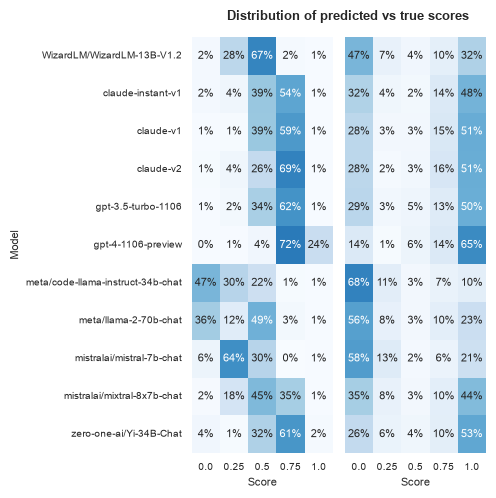

In [6]:
binned_model_preds = get_bin_counts(scores, normal=True)
binned_model_scores = get_bin_counts(S)
fig = heatmap_comparison(binned_model_preds, binned_model_scores)

if EXPORT_FIG:
    fig.savefig(save_prefix + "predicted_score_distribution.png")

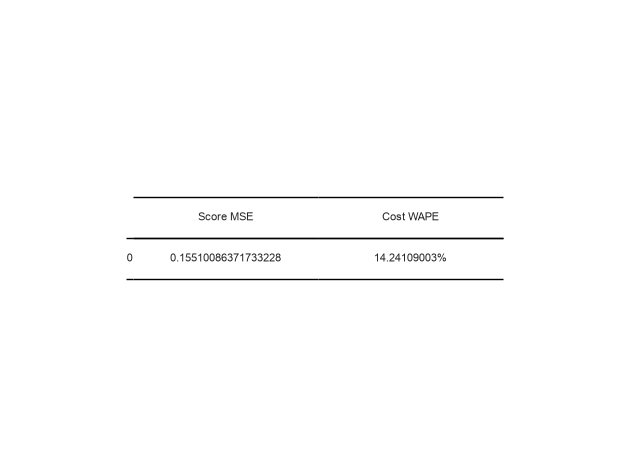

In [7]:
score_mse = np.square(S-scores).to_numpy().sum() / (S.shape[0] * S.shape[1])
cost_wape = np.abs(C-costs).to_numpy().sum() / C.to_numpy().sum()

total_errors = pd.DataFrame([{'Score MSE': score_mse, 'Cost WAPE': cost_wape}])
total_errors["Cost WAPE"] = total_errors["Cost WAPE"].map('{:.8%}'.format)

# save as table
fig, ax = plt.subplots()
ax.axis("off")
tbl = pd.plotting.table(ax, total_errors, loc="center", cellLoc="center", 
                  colWidths=[0.2, 0.2], edges='horizontal')
tbl.scale(1.5, 2.0)
plt.tight_layout()

if EXPORT_FIG:
    fig.savefig(save_prefix + "regression_metrics.png", bbox_inches="tight", pad_inches=0)

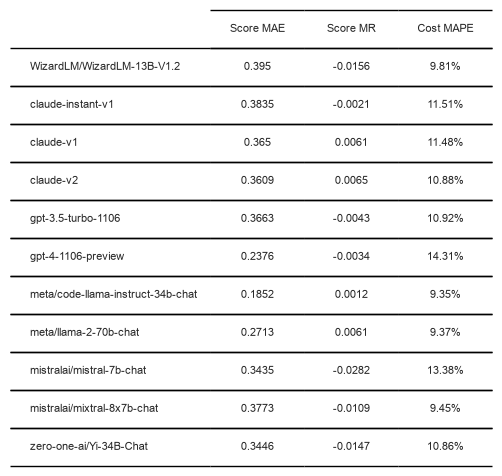

In [8]:
errors = pd.DataFrame(abs(S-scores).mean(axis=0), columns=["Score MAE"])
errors["Score MR"] = (S-scores).mean(axis=0)
errors["Cost MAPE"] = (100 * abs(C-costs) / costs).mean(axis=0).map('{:,.2f}%'.format)

# save as table
fig, ax = plt.subplots()
ax.axis("off")
pd.plotting.table(ax, errors.round(4), loc="center", cellLoc="center", bbox=[0, 0, 1, 1], 
                        colWidths=[0.2, 0.2, 0.2], edges='horizontal')
plt.tight_layout()

if EXPORT_FIG:
    fig.savefig(save_prefix + "regression_metrics_by_model.png", bbox_inches="tight", pad_inches=0)

**Results:** Score MSE is 0.1551009 and pooled cost WAPE is 14.24109003%. This WAPE pools all entries, unlike training’s equal-weight average of per-model WAPEs. Expected-score distributions are more concentrated than recorded grades.

## 4. Residuals by model and task

Plot recorded minus predicted score by candidate and for the 12 most frequent tasks. Positive residuals mean underprediction; negative residuals mean overprediction.

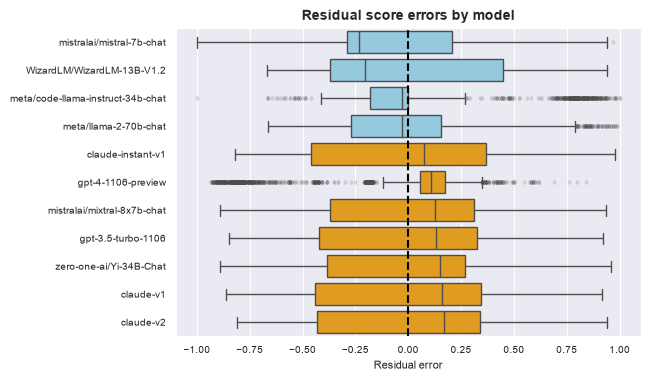

In [9]:
residuals = S-scores
medians   = residuals.median()

# sort by median value
index_sort = medians.sort_values().index
sorted_residuals = residuals[index_sort]

# assign colors based on the median sign
def assign_color(r):
    if r < 0: 
        return "skyblue"
    elif r > 0: 
        return "orange"
    else: 
        return "gray"
        
colors = medians.map(assign_color).to_dict()

plt.figure(figsize=(6,4))
sns.boxplot(sorted_residuals, orient='h', palette=colors,
            fliersize=2, flierprops={"marker": "d", "alpha": 0.2},)
plt.axvline(x=0, c='k', linestyle='--')
plt.xlabel('Residual error')
plt.title('Residual score errors by model', fontweight="bold")

if EXPORT_FIG:
    plt.savefig(save_prefix + 'residual_score_errors_by_model.png', bbox_inches="tight", pad_inches=0)

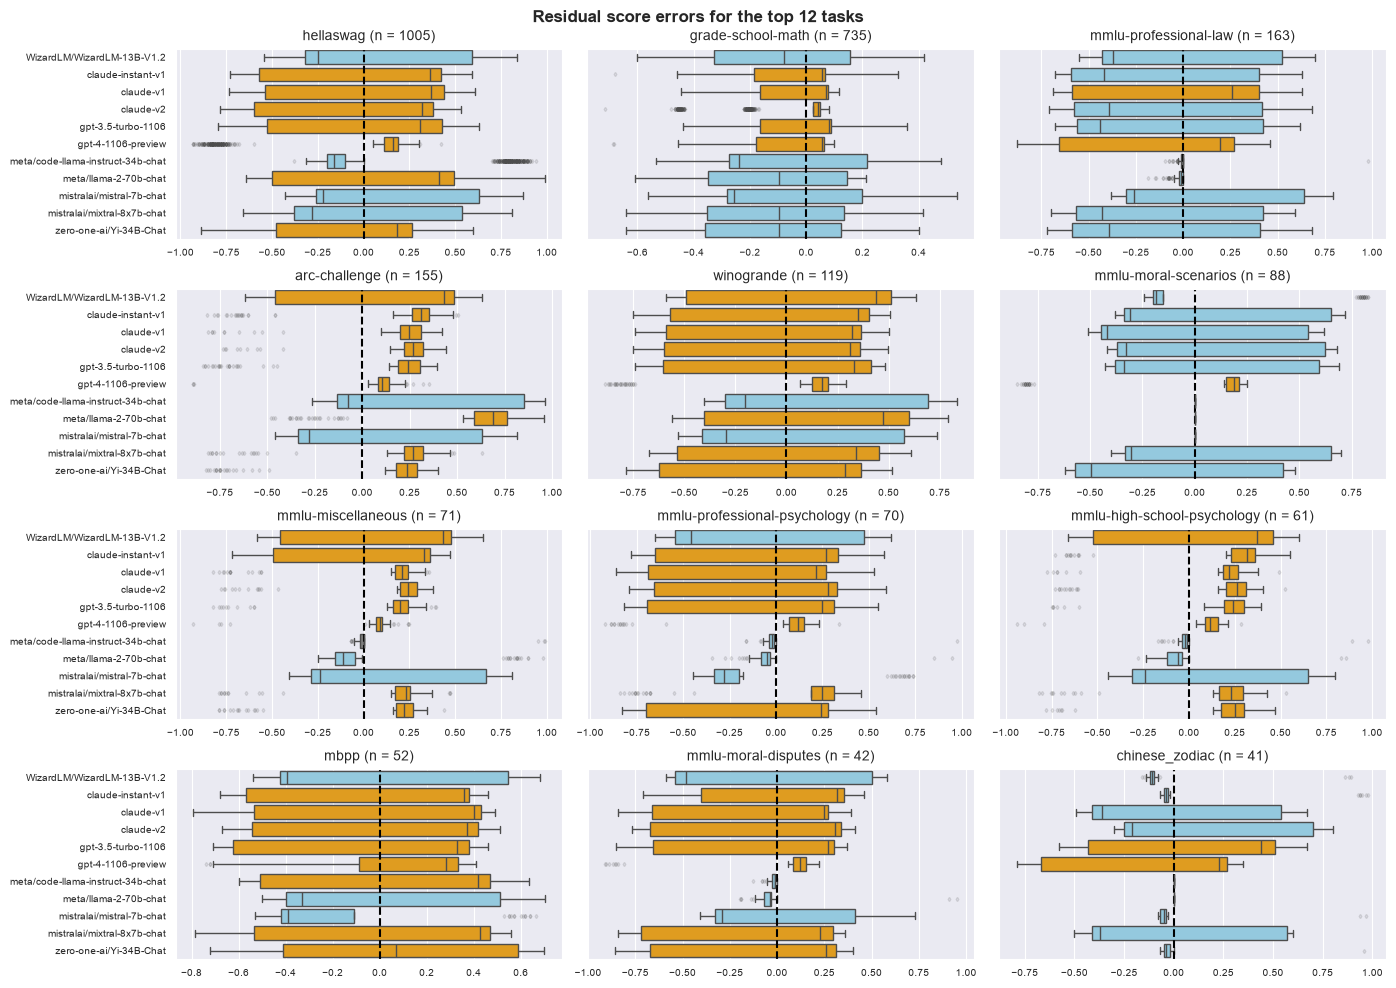

In [10]:
num_tasks = 12
tasks, _ = get_top_tasks(Q, num=num_tasks)
tasks    = tasks.index.to_list()
labeled_residuals = residuals.join(Q["eval_name"], how="left")

fig, axs = plt.subplots(nrows=4, ncols=3, figsize=(14,10))
axs = axs.flatten()

for i in range(num_tasks):
    t = tasks[i]
    task_res = labeled_residuals[labeled_residuals["eval_name"] == t]
    task_med = task_res.iloc[:, :-1].median()
    
    # assign colors based on the median sign
    colors = task_med.map(assign_color).to_dict()

    ax = axs[i]
    sns.boxplot(data=task_res, ax=ax, orient='h', palette=colors,
                fliersize=2, flierprops={"marker": "d", "alpha": 0.2},)
    
    if i % 3 != 0:
        ax.set_yticklabels([])
        
    ax.axvline(x=0, c='k', linestyle='--')
    ax.set_title(f'{t} (n = {len(task_res)})')

plt.suptitle(f'Residual score errors for the top {num_tasks} tasks', 
             fontsize=12, fontweight="bold")
plt.tight_layout()

if EXPORT_FIG:
    plt.savefig(save_prefix + 'residual_score_errors_by_task.png', bbox_inches="tight", pad_inches=0);

**Results:** The overall plot shows different residual distributions across candidates: GPT-4 has a positive median and Mistral-7B a negative median. Task panels support a closer inspection of where errors occur.

## 5. Pairwise model comparisons

Compare predicted and recorded pairwise win rates, tie rates and mean score differences. Win-rate plots credit ties as half a win.

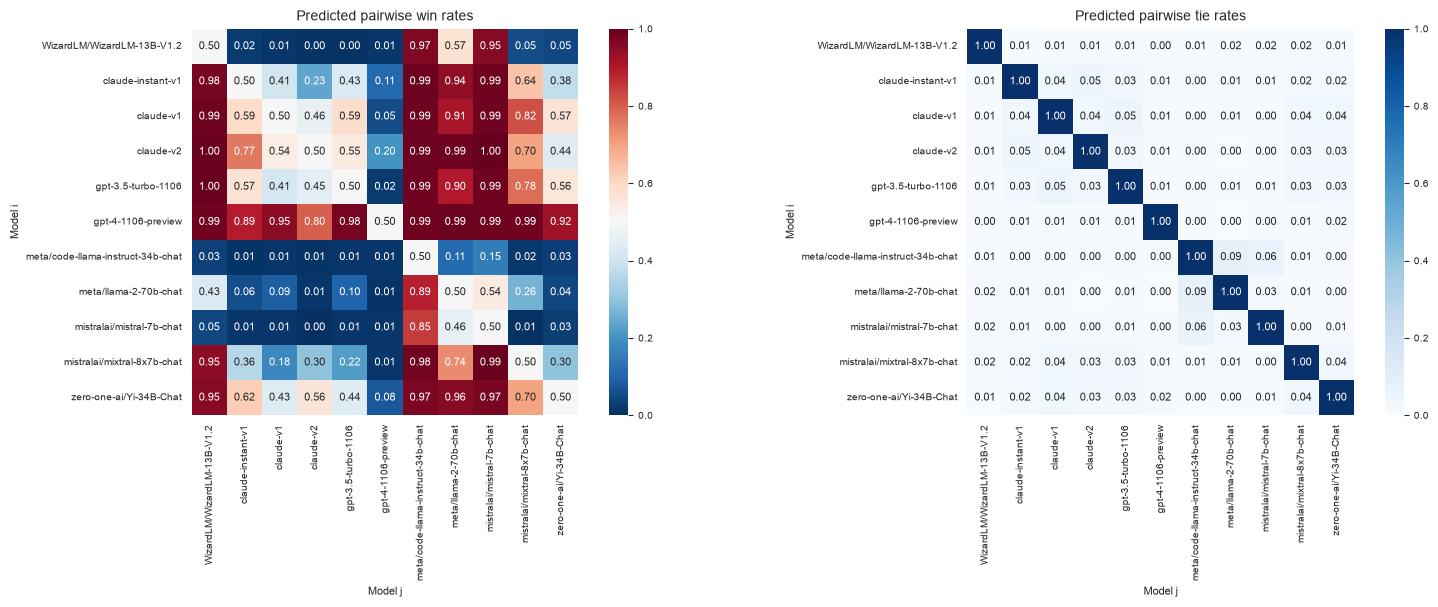

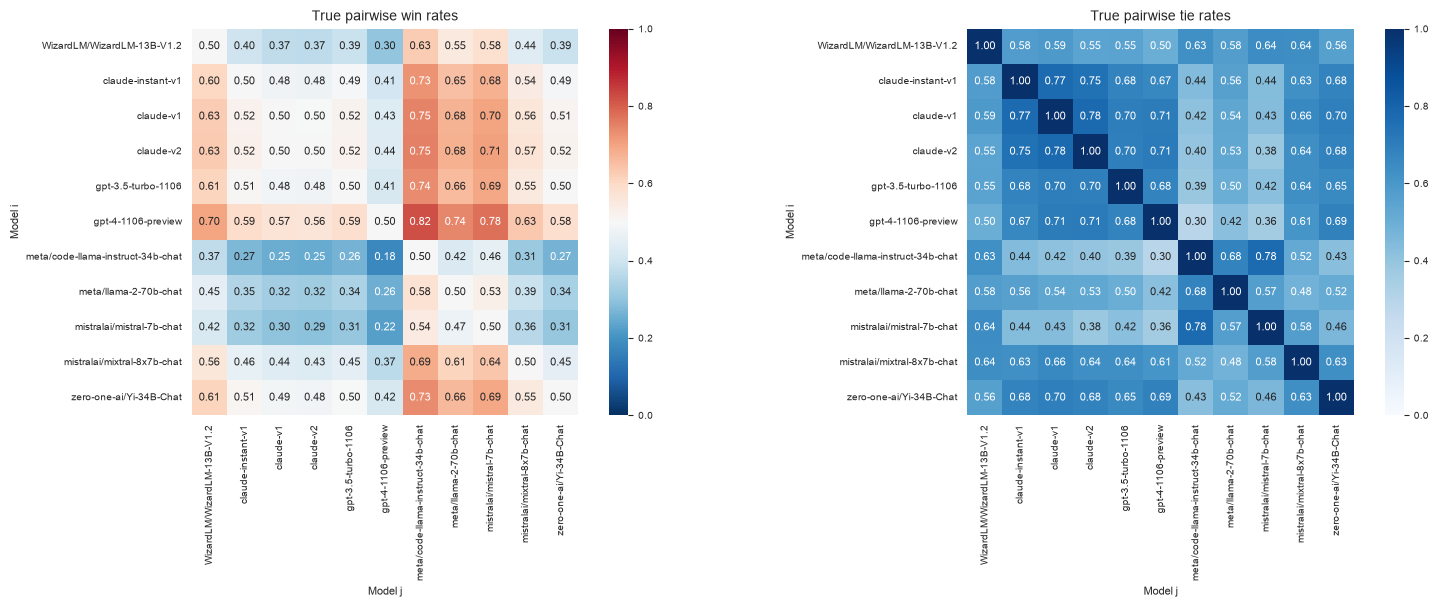

In [11]:
pred_fig, _, _ = plot_pairwise_win_rates(scores, title_prefix='Predicted')
true_fig, _, _ = plot_pairwise_win_rates(S, title_prefix='True')

if EXPORT_FIG:
    pred_fig.savefig(save_prefix + 'predicted_win_tie_rates.png', bbox_inches="tight", pad_inches=0)
    true_fig.savefig(save_prefix + 'true_win_tie_rates.png', bbox_inches="tight", pad_inches=0);

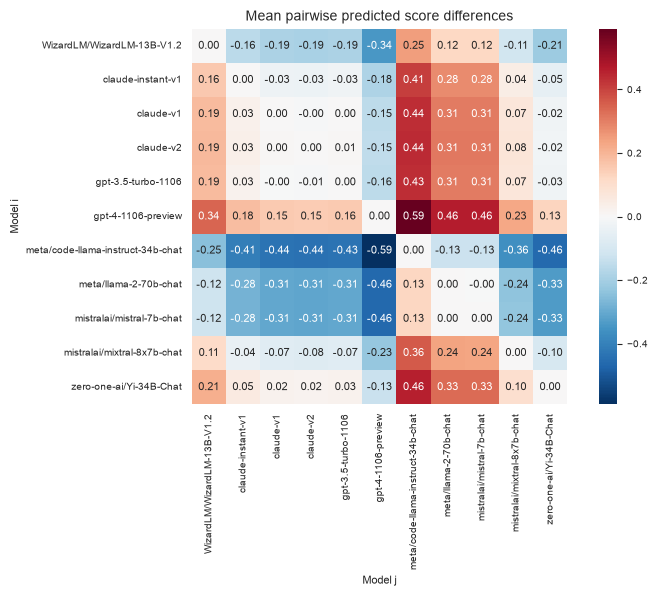

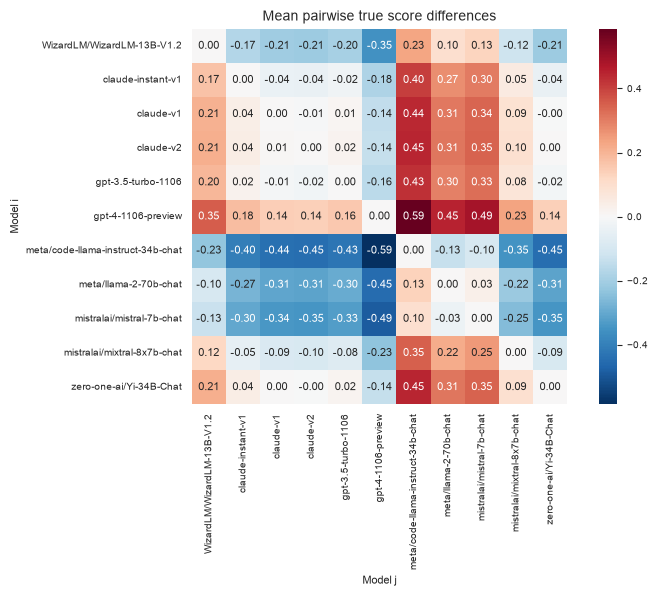

In [12]:
pred_fig, _ = plot_pairwise_differences(scores, title_prefix="predicted")
true_fig, _ = plot_pairwise_differences(S, title_prefix="true")

if EXPORT_FIG:
    pred_fig.savefig(save_prefix + 'predicted_score_differences.png', bbox_inches="tight", pad_inches=0)
    true_fig.savefig(save_prefix + 'true_score_differences.png', bbox_inches="tight", pad_inches=0);

**Results:** The heatmaps compare candidate rankings under predictions and recorded outcomes. These are descriptive comparisons on the same validation prompts, not an independent test.

## 6. Evaluate individual routing policies

Select the model maximizing **predicted score − λ × predicted dollar cost** (`argmax`). Larger λ penalizes cost more strongly. Evaluate λ = 0.1, inspect its top-task errors, then evaluate λ = 1000 using recorded outcomes.

In [13]:
%%time
# instantiate a class to analyze the prediction results using lambda = 0.1
policy = DecisionPolicy(
    predictions,
    truths,
    l=0.1,
    show=True
)

===========Statistics for l=0.1===========

How often each model is selected:


best_model
gpt-4-1106-preview                   71.94%
claude-v2                            17.70%
zero-one-ai/Yi-34B-Chat               6.96%
claude-instant-v1                     1.59%
mistralai/mistral-7b-chat             0.47%
gpt-3.5-turbo-1106                    0.38%
meta/code-llama-instruct-34b-chat     0.38%
mistralai/mixtral-8x7b-chat           0.33%
claude-v1                             0.16%
meta/llama-2-70b-chat                 0.05%
WizardLM/WizardLM-13B-V1.2            0.03%
Name: proportion, dtype: str

Performance: 0.790600
Cost: $0.002487
CPU times: user 2.46 ms, sys: 366 μs, total: 2.83 ms
Wall time: 2.84 ms


In [14]:
# compute some error metrics for the top 10 tasks
policy.evaluate_top_tasks(Q)

,Count,Score MR,Score MAE,Cost MAPE
Task,,,,
hellaswag,1005,0.012831,0.262537,6.41%
grade-school-math,735,-0.042075,0.109850,13.70%
mmlu-professional-law,163,-0.057515,0.413834,9.55%
arc-challenge,155,0.099065,0.133452,17.10%
winogrande,119,-0.036513,0.330840,39.37%
mmlu-moral-scenarios,88,-0.030000,0.335227,9.42%
mmlu-miscellaneous,71,0.047465,0.138380,16.89%
mmlu-professional-psychology,70,-0.058500,0.273429,10.39%
mmlu-high-school-psychology,61,0.078115,0.164344,11.81%


In [15]:
# example use of evaluate_lambda method to evaluate the policy for a different lambda
per, cost = policy.evaluate_lambda(1000)

print(f"Performance: {per:.4f}")
print(f"Cost: ${cost:.6f}")

Performance: 0.6502
Cost: $0.000119


**Results:** At λ = 0.1, mean score is 0.790600 and mean cost is $0.002487; GPT-4 receives 71.94% of prompts. At λ = 1000, mean score is 0.6502 and cost is $0.000119.

## 7. Validation cost–score tradeoff

Evaluate 201 λ values: zero plus a logarithmic grid from 0.001 to 5000. Compare policies with fixed GPT-4, fixed Mistral-7B and an oracle that uses recorded scores to choose each model.

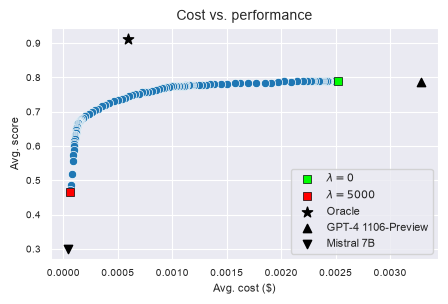

In [16]:
l_max = 5000
L = np.concatenate([[0],np.geomspace(0.001, l_max, 200)])
analysis = DecisionPolicy(predictions, truths, l=0, show=False)
results = policy.evaluate_lambdas(L)

# compute oracle
oracle_idx = S.idxmax(axis=1)
oracle_idx = S.columns.get_indexer(oracle_idx)
oracle_scores = S.max(axis=1)
oracle_costs = C.to_numpy()[np.arange(len(C)), oracle_idx]

os = oracle_scores.mean()
oc = oracle_costs.mean()

# compute gpt
gs = S['gpt-4-1106-preview'].mean()
gc = C['gpt-4-1106-preview'].mean()

# compute mistral
ms = S['mistralai/mistral-7b-chat'].mean()
mc = C['mistralai/mistral-7b-chat'].mean()

# plot cost vs accuracy
plt.figure(figsize=(5,3))

sns.scatterplot(results, x='cost', y='performance')
sns.scatterplot(results[results.index == 0], x='cost', y='performance',
                c='lime', edgecolors='k', marker='s', label=r'$\lambda=0$')
sns.scatterplot(results[results.index == l_max], x='cost', y='performance', 
                c='r', edgecolors='k', marker='s', label=r'$\lambda='+str(l_max)+'$')

# plot reference points
plt.scatter(oc, os, color='k', marker='*', s=60, label='Oracle')
plt.scatter(gc, gs, color='k', marker='^', label='GPT-4 1106-Preview')
plt.scatter(mc, ms, color='k', marker='v', label='Mistral 7B')

plt.title('Cost vs. performance')
plt.xlabel('Avg. cost ($)')
plt.ylabel('Avg. score')
plt.legend()

if EXPORT_FIG:
    plt.savefig(save_prefix + "cost_performance_curve.png", bbox_inches="tight", pad_inches=0);

**Results:** The scatterplot shows discrete validation policy outcomes. The oracle uses unavailable outcome knowledge and serves only as a benchmark; the vertical axis is mean grade, not binary accuracy.

## 8. Fit the curve and select a quality threshold

Fit a descriptive saturating curve using costs in millidollars. Set the score threshold to GPT-4’s validation mean, then separately select the cheapest observed grid policy meeting it.

In [17]:
from scipy.optimize import curve_fit

x = results["cost"].to_numpy() * 1000  # Convert to millidollars
y = results["performance"].to_numpy()
x0 = x.min()

def fitting_curve(x, a, b, tau, p):
    z = np.maximum(x - x0, 0)
    return a + b * (1 - np.exp(-z**p / tau))

def inverse_fitting_curve(y, a, b, tau, p):
    z = np.maximum(x - x0, 0)
    return x0 + (tau * np.log(b / (a + b - y))) ** (1/p)

params, _ = curve_fit(
    fitting_curve,
    x,
    y,
    p0=[y.min(), y.max() - y.min(), 0.5, 0.5],
    bounds=([0, 0, 1e-8, 0.01], [1, 1, np.inf, 1]),
    maxfev=20000
)

The fitted cost $0.002092 corresponds to a -36.22% change compared to GPT-4.
The cheapest lambda achieving the minimum performance is: l = 2.7142066911362983


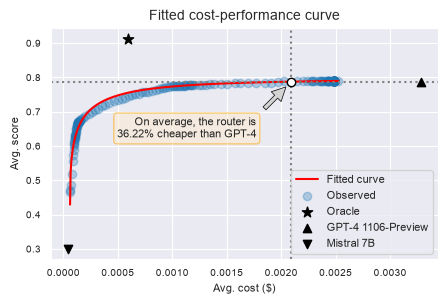

In [18]:
# Set the performance threshold. Default value = GPT
T = gs

# find the associated cost using the inverse curve
inv_T = inverse_fitting_curve(T, *params) / 1000

# find the closest lambda that achieves the minimum tolerance for the cheapest ccost
l_T = policy.select_lambda_from_threshold(l_values=L, threshold=T)

cost_saving = 100 * (gc-inv_T) / gc * np.sign(inv_T-gc)
print(f'The fitted cost ${inv_T:0.6f} corresponds to a {cost_saving:0.2f}% change compared to GPT-4.')
print(f'The cheapest lambda achieving the minimum performance is: l = {l_T}')

# plot fitted curve
x_fit = np.linspace(x.min(), x.max(), 500)
y_fit = fitting_curve(x_fit, *params)

plt.figure(figsize=(5,3))
plt.plot(x_fit / 1000, y_fit, 'r', label="Fitted curve")
plt.scatter(x / 1000, y, label="Observed", alpha=0.3)

# plot reference points
plt.scatter(oc, os, color='k', marker='*', s=60, label='Oracle')
plt.scatter(gc, gs, color='k', marker='^', label='GPT-4 1106-Preview', zorder=3)
plt.scatter(mc, ms, color='k', marker='v', label='Mistral 7B')

# plot tolerance line
plt.axhline(y=T, color='gray', linestyle=':')
plt.axvline(x=inv_T, color='gray', linestyle=':')
plt.scatter(inv_T, T, color='w', edgecolors='k', zorder=4)

plt.title('Fitted cost-performance curve')
plt.xlabel("Avg. cost ($)")
plt.ylabel("Avg. score")
plt.legend(loc="lower right")

# add "caption" inside the plot area
plt.annotate(f"On average, the router is\n{np.abs(cost_saving):.2f}% cheaper than GPT-4", xy=(inv_T, T), 
             xytext=(-25,-25), textcoords='offset points',
             horizontalalignment='right', verticalalignment='top',
             arrowprops=dict(facecolor='lightgray', ec='k', lw=0.5, 
                             width=3, headwidth=10, headlength=10, shrink=0.15),
             bbox=dict(boxstyle="round", fc='blanchedalmond', ec='orange', alpha=0.5))

if EXPORT_FIG:
    plt.savefig(save_prefix + "fitted_cost_performance_curve.png", bbox_inches="tight", pad_inches=0);

**Results:** The fitted curve estimates $0.002092 at the threshold, or 36.22% below GPT-4’s historical cost. The selected discrete policy has λ = 2.7142066911362983; the curve estimate is not its measured cost.

## 9. Inspect the selected validation policy

Apply the selected λ and display its actual validation score, cost and model-selection shares.

In [19]:
# view the model selections made by the corresponding lambda

policy = DecisionPolicy(
    predictions,
    truths,
    l=l_T,
    show=True
)

===========Statistics for l=2.7142066911362983===========

How often each model is selected:


best_model
gpt-4-1106-preview                   70.07%
claude-v2                            12.11%
claude-instant-v1                     7.78%
zero-one-ai/Yi-34B-Chat               7.32%
gpt-3.5-turbo-1106                    1.01%
mistralai/mistral-7b-chat             0.47%
mistralai/mixtral-8x7b-chat           0.44%
meta/code-llama-instruct-34b-chat     0.44%
claude-v1                             0.27%
meta/llama-2-70b-chat                 0.05%
WizardLM/WizardLM-13B-V1.2            0.03%
Name: proportion, dtype: str

Performance: 0.788531
Cost: $0.002029


**Results:** The selected kNN-score/XGBoost-cost policy with TF-IDF achieves mean score 0.788531 at $0.002029 per response, with GPT-4 selected 70.07% of the time. Historical response-cost savings are 38.13% relative to GPT-4, excluding router overhead. The policy and λ were selected on validation; this is not an independent test result. This configuration differs from the kNN/E5 policy evaluated in `4_Final_Test/`.